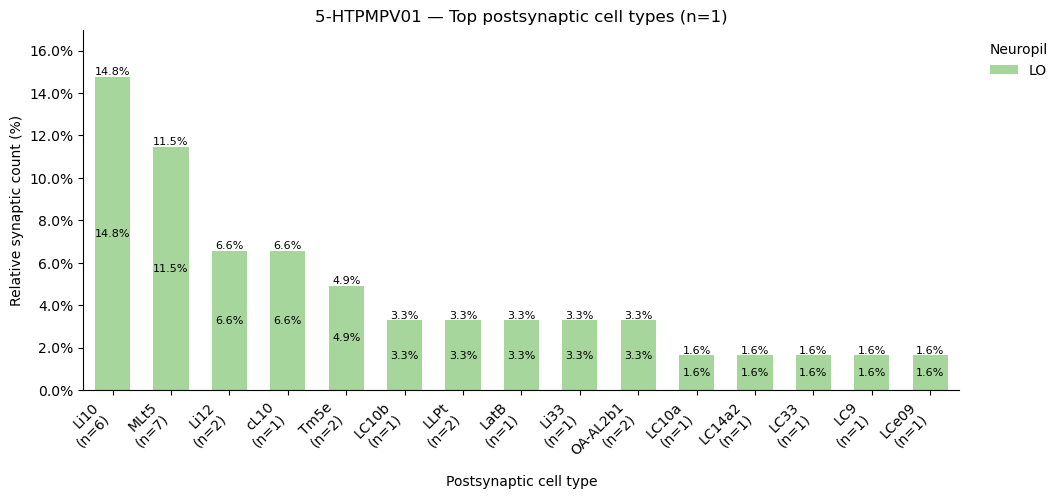

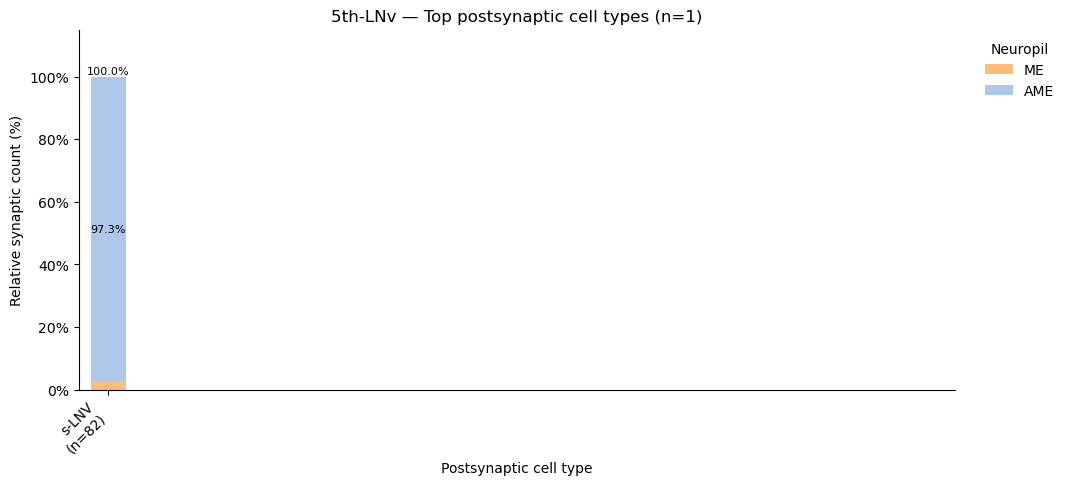

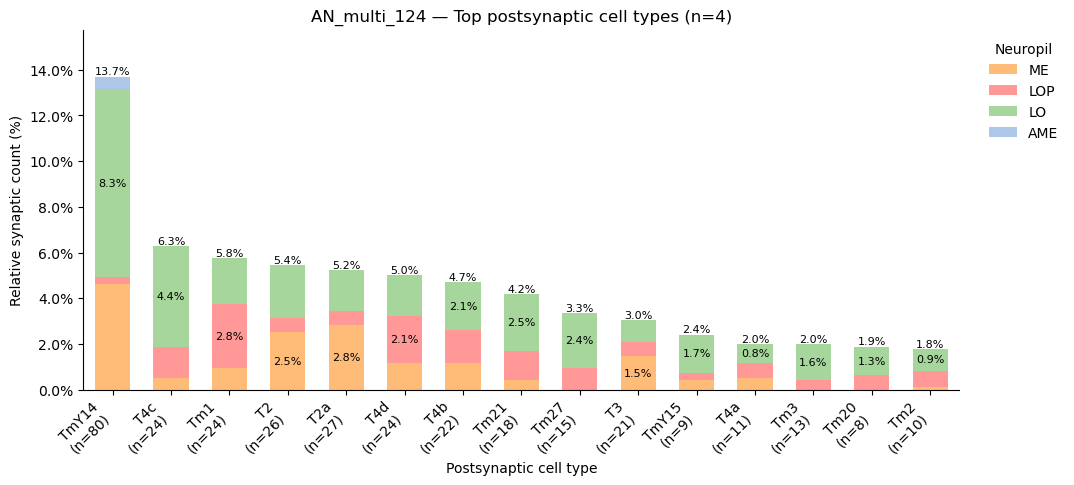

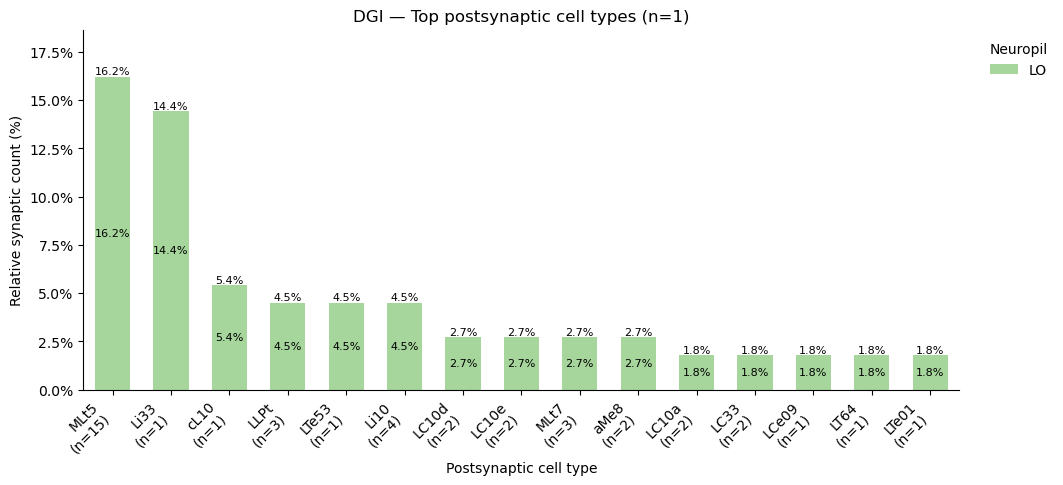

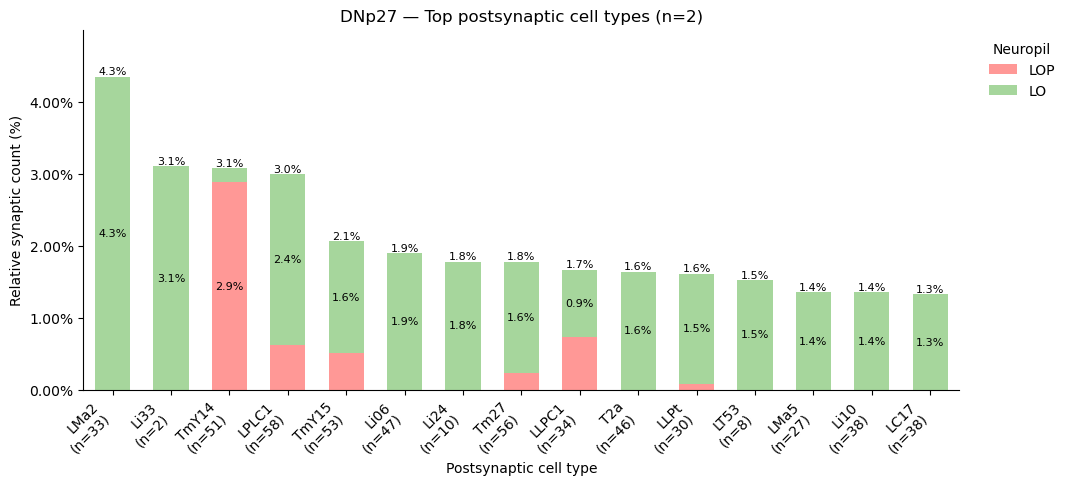

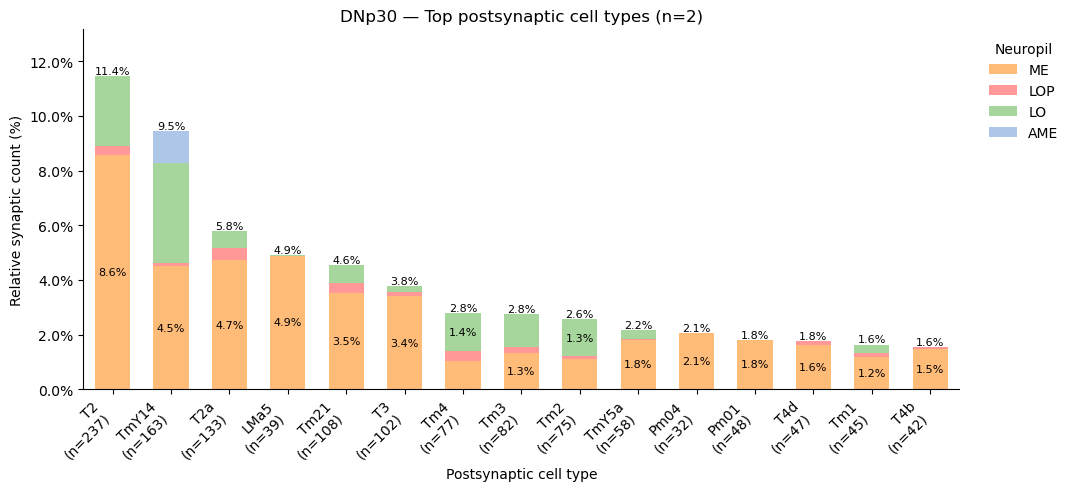

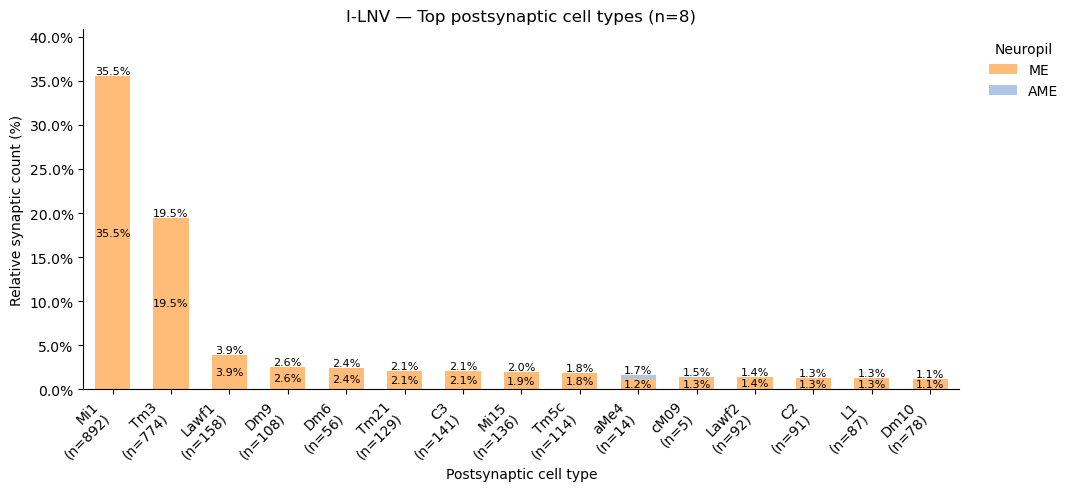

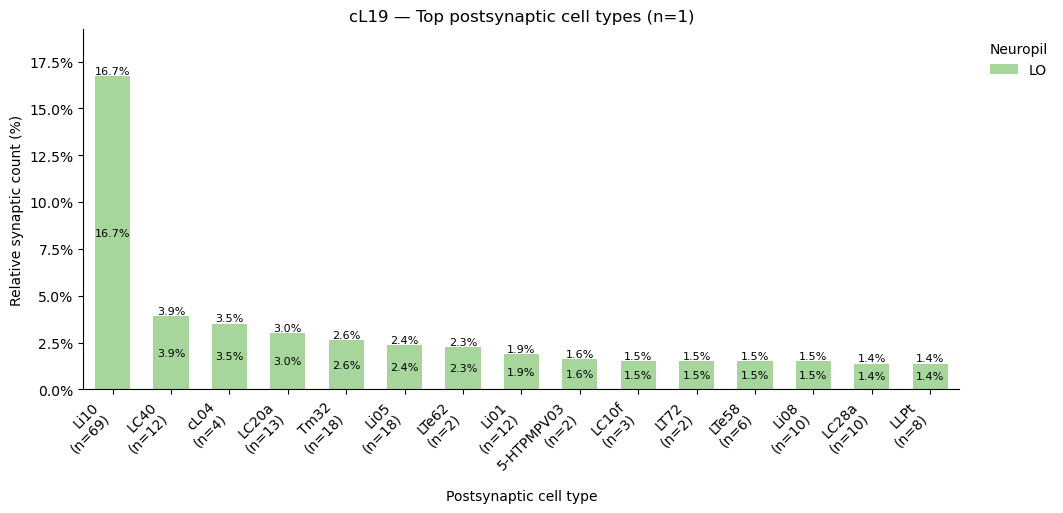

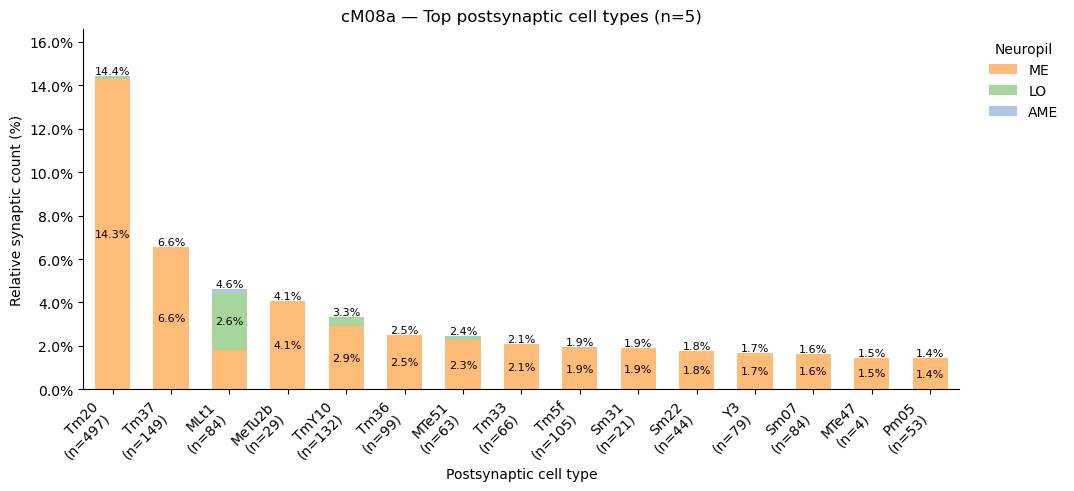

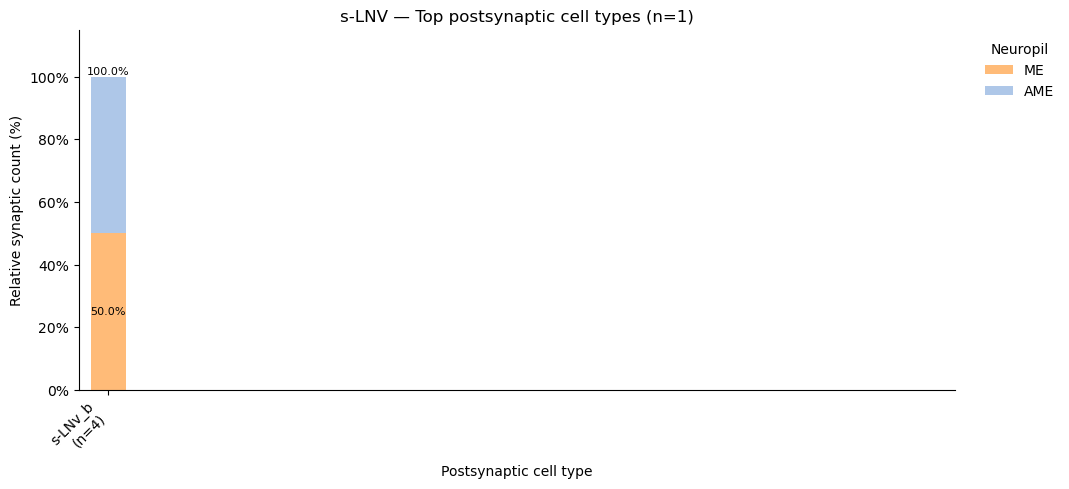

In [1]:
#plot for each neuropil showing the distribution of postsynaptic cell types for each presynaptic cell type.

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

df = pd.read_csv(
    "/Users/ndutta/Drive D/B mod/missing_ids_connections_with_cell_types_renamed.csv",
    dtype={"pre_root_id": "string", "post_root_id": "string"}
)

pre, post = "pre_syn_cell_types", "post_syn_cell_types"
names = {
    "ilnv": "I-LNV",
    "dnp30, dskmp1a": "DNp30",
    "dnp30, dskmp1": "DNp30",
    "s-lnv_a, s-lnv": "s-LNV",
    "slnv_a s-lnv": "s-LNV",
    "s-lnv": "s-LNV",
    "slnv": "s-LNV"
}

for column in [pre, post]:
    df[column] = df[column].fillna("Unannotated").str.strip()
    df[column] = df[column].apply(
        lambda name: names.get(name.lower(), name)
    )

colors = {"ME": "#FFBB78", "LOP": "#FF9896",
          "LO": "#A6D69C", "AME": "#AEC7E8"}
df["neuropil"] = df["neuropil"].str.replace(r"_[LR]$", "", regex=True)
df = df[df["neuropil"].isin(colors) & (df["syn_count"] > 0)]

for name, data in df.groupby(pre):
    n = data.groupby(post)["post_root_id"].nunique()
    counts = data.pivot_table(
        index=post, columns="neuropil", values="syn_count",
        aggfunc="sum", fill_value=0
    ).reindex(columns=list(colors), fill_value=0)

    top = (
        counts.drop(index="Unannotated", errors="ignore")
        .sum(axis=1).nlargest(15).index
    )
    bars = counts.loc[top] / data["syn_count"].sum()
    bars = bars.loc[:, bars.sum() > 0]
    if bars.empty:
        continue

    ax = bars.plot.bar(
        stacked=True, figsize=(12, 6), width=.6,
        color=[colors[c] for c in bars.columns]
    )

    for i in range(len(bars)):
        row = bars.iloc[i]
        j = row.argmax()
        ax.text(i, row.iloc[:j].sum() + row.iloc[j] / 2,
                f"{row.iloc[j]:.1%}", ha="center", va="center", fontsize=8)
        ax.text(i, row.sum(), f"{row.sum():.1%}",
                ha="center", va="bottom", fontsize=8)

    ax.set_xticks(
        range(len(top)), [f"{t}\n(n={n[t]})" for t in top],
        rotation=45, ha="right"
    )
    ax.set(
        xlim=(-.5, 14.5),
        title=f"{name} — Top postsynaptic cell types (n={data['pre_root_id'].nunique()})",
        xlabel="Postsynaptic cell type",
        ylabel="Relative synaptic count (%)",
        ylim=(0, bars.sum(axis=1).max() * 1.15)
    )
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(title="Neuropil", bbox_to_anchor=(1.02, 1),
              loc="upper left", frameon=False)

    plt.subplots_adjust(left=.10, right=.83, bottom=.30, top=.90)
    plt.show()
    plt.close(ax.figure)

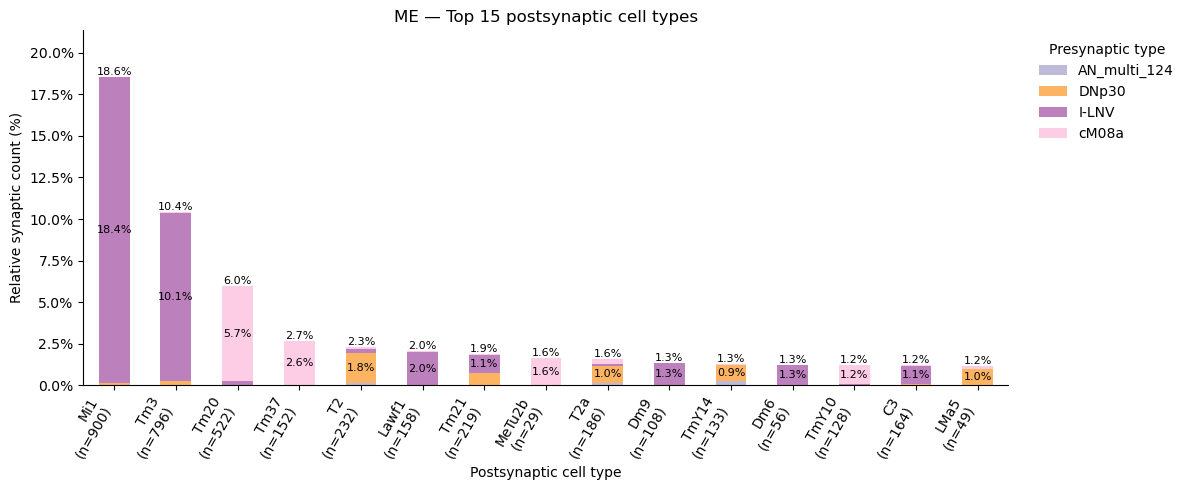

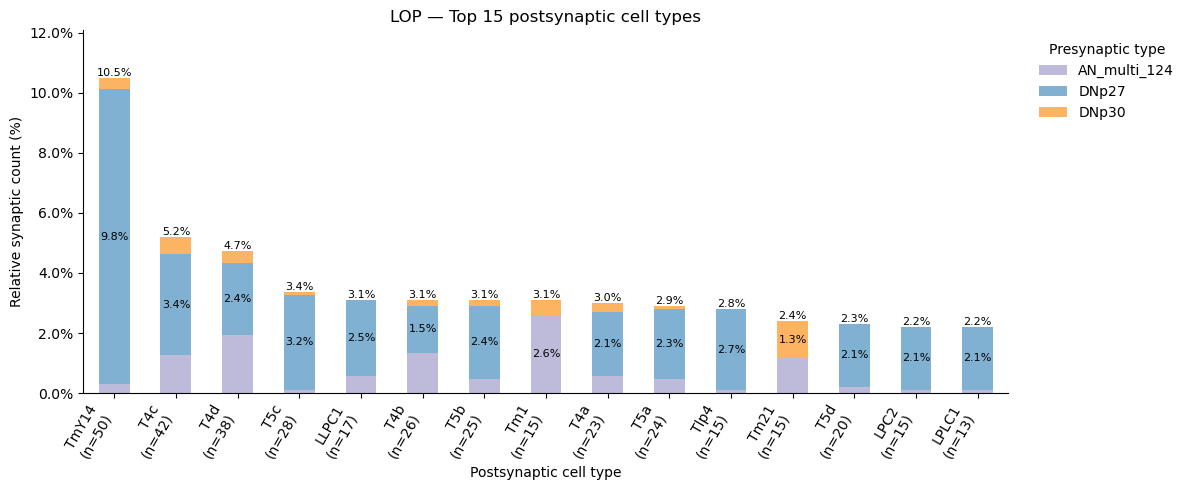

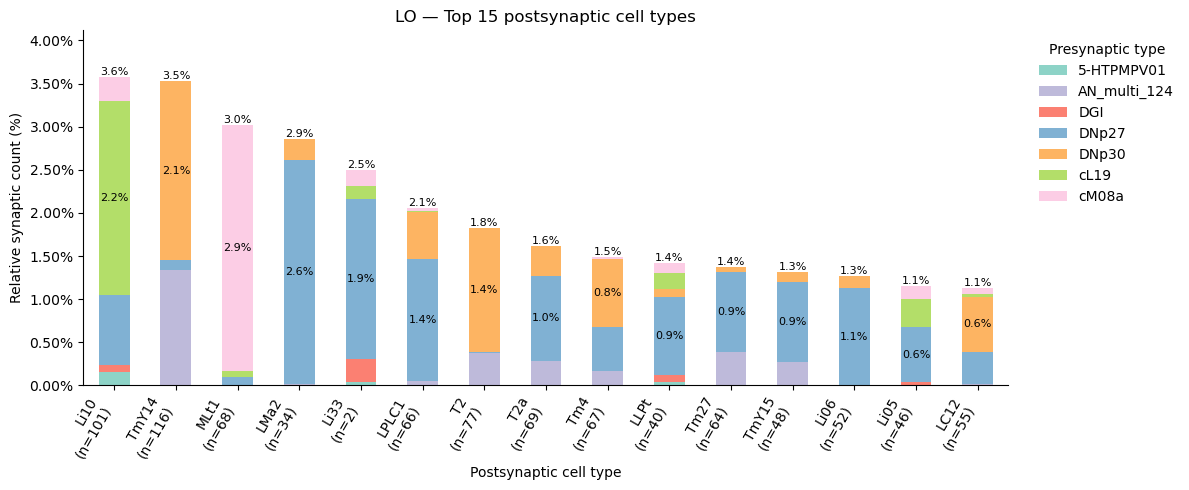

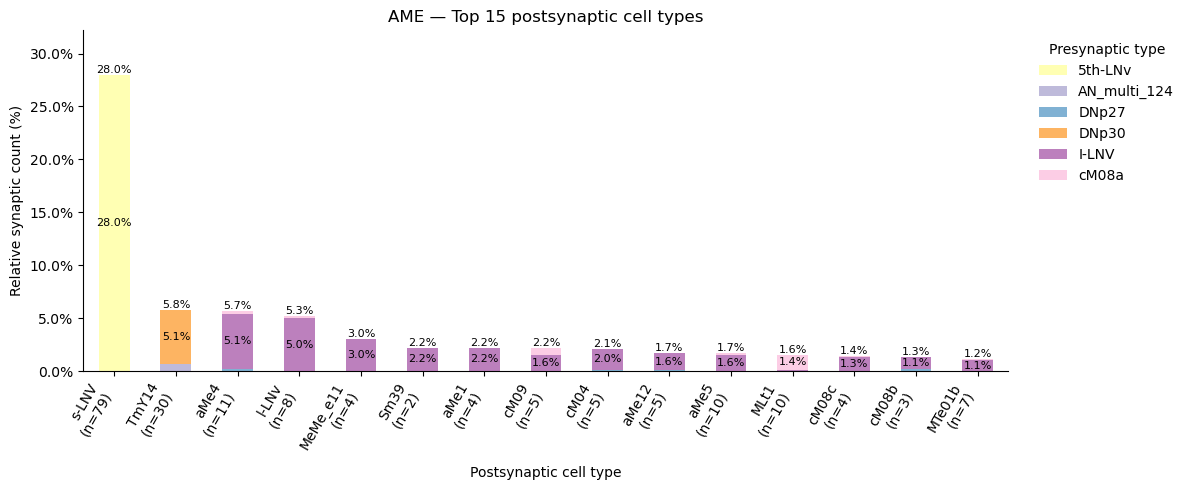

In [2]:
#bar plot for each neuropil showing the distribution of postsynaptic cell types for each presynaptic cell type.  
# Each plot displays the top 15 postsynaptic cell types in a given neuropil, 
# bars representing the relative synaptic counts contributed by different presynaptic cell types.

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

df = pd.read_csv(
    "/Users/ndutta/Drive D/B mod/final_connections_fixed_names.csv",
    dtype={"pre_root_id": "string", "post_root_id": "string"}
)

pre, post = "pre_syn_cell_types", "post_syn_cell_types"
df[[pre, post]] = df[[pre, post]].fillna("Unannotated")
df["neuropil"] = df["neuropil"].str.replace(r"_[LR]$", "", regex=True)

colors = {
    "5-HTPMPV01": "#8DD3C7",
    "5th-LNv": "#FFFFB3",
    "AN_multi_124": "#BEBADA",
    "DGI": "#FB8072",
    "DNp27": "#80B1D3",
    "DNp30": "#FDB462",
    "cL19": "#B3DE69",
    "cM08a": "#FCCDE5",
    "I-LNV": "#BC80BD",
    "s-LNV": "#CCEBC5",
    "Unannotated": "#D9D9D9"
}

missing = set(df[pre].unique()) - set(colors)
assert not missing, f"Add colors for: {missing}"

for region in ["ME", "LOP", "LO", "AME"]:
    data = df[(df["neuropil"] == region) & (df["syn_count"] > 0)]
    if data.empty:
        continue

    counts = data.pivot_table(
        index=post, columns=pre, values="syn_count",
        aggfunc="sum", fill_value=0
    )
    top = (
        counts.drop(index="Unannotated", errors="ignore")
        .sum(axis=1).nlargest(15).index
    )
    bars = counts.loc[top]
    bars = bars.loc[:, bars.sum() > 0] / data["syn_count"].sum()
    if bars.empty:
        continue

    n = data.groupby(post)["post_root_id"].nunique()

    ax = bars.plot.bar(
        stacked=True, figsize=(12, 5),
        color=[colors[c] for c in bars.columns]
    )

    for i in range(len(bars)):
        row = bars.iloc[i]
        j = row.argmax()
        ax.text(i, row.iloc[:j].sum() + row.iloc[j] / 2,
                f"{row.iloc[j]:.1%}", ha="center", va="center", fontsize=8)
        ax.text(i, row.sum(), f"{row.sum():.1%}",
                ha="center", va="bottom", fontsize=8)

    ax.set_xticks(
        range(len(top)), [f"{t}\n(n={n[t]})" for t in top],
        rotation=60, ha="right"
    )
    ax.set(
        title=f"{region} — Top 15 postsynaptic cell types",
        xlabel="Postsynaptic cell type",
        ylabel="Relative synaptic count (%)",
        ylim=(0, bars.sum(axis=1).max() * 1.15)
    )
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(
        title="Presynaptic type", bbox_to_anchor=(1.02, 1),
        loc="upper left", frameon=False
    )

    plt.tight_layout()
    plt.show()
    plt.close(ax.figure)

    # 

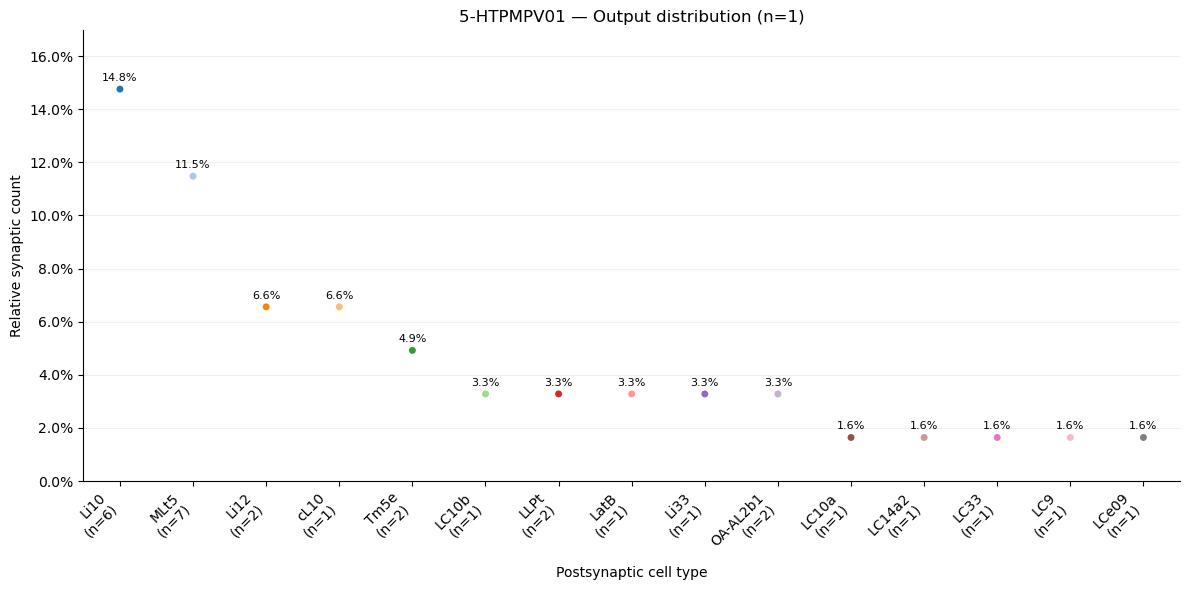

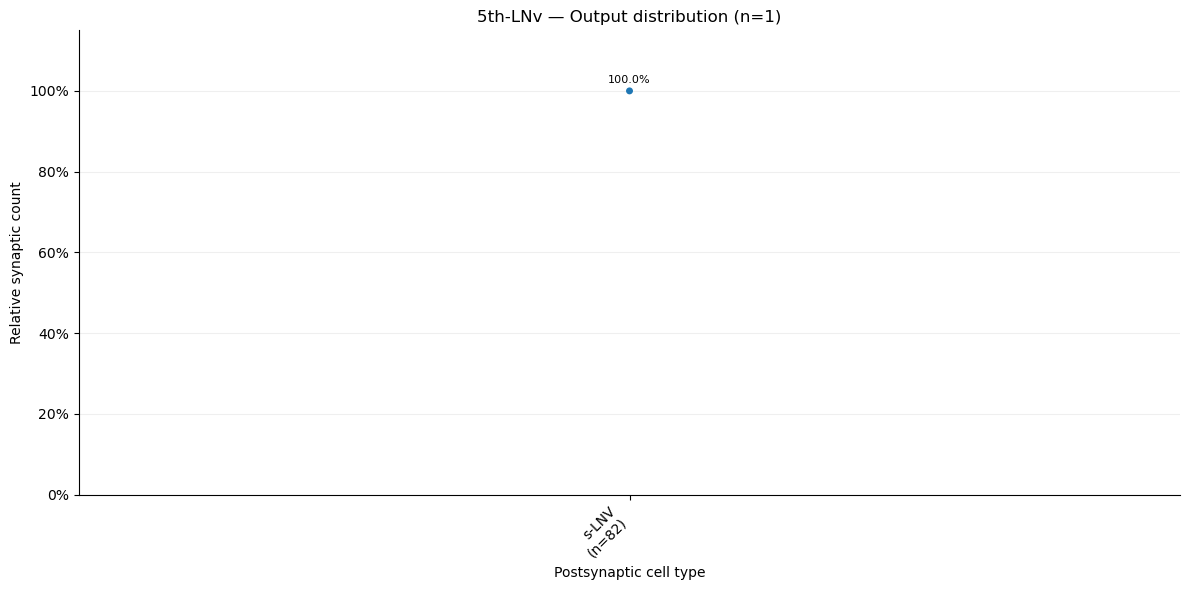

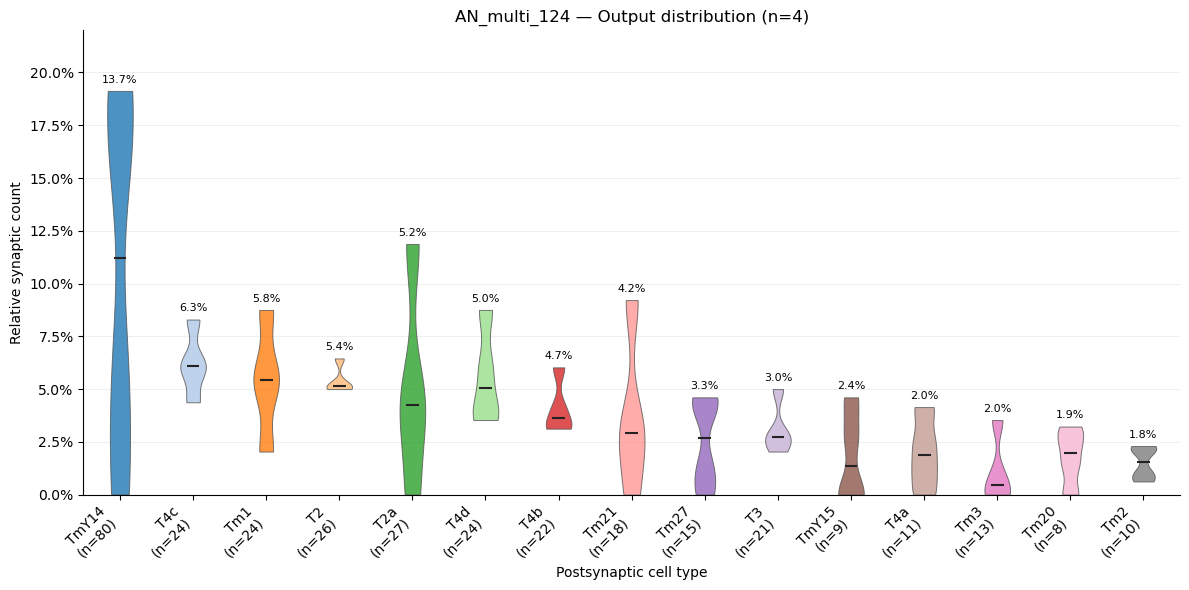

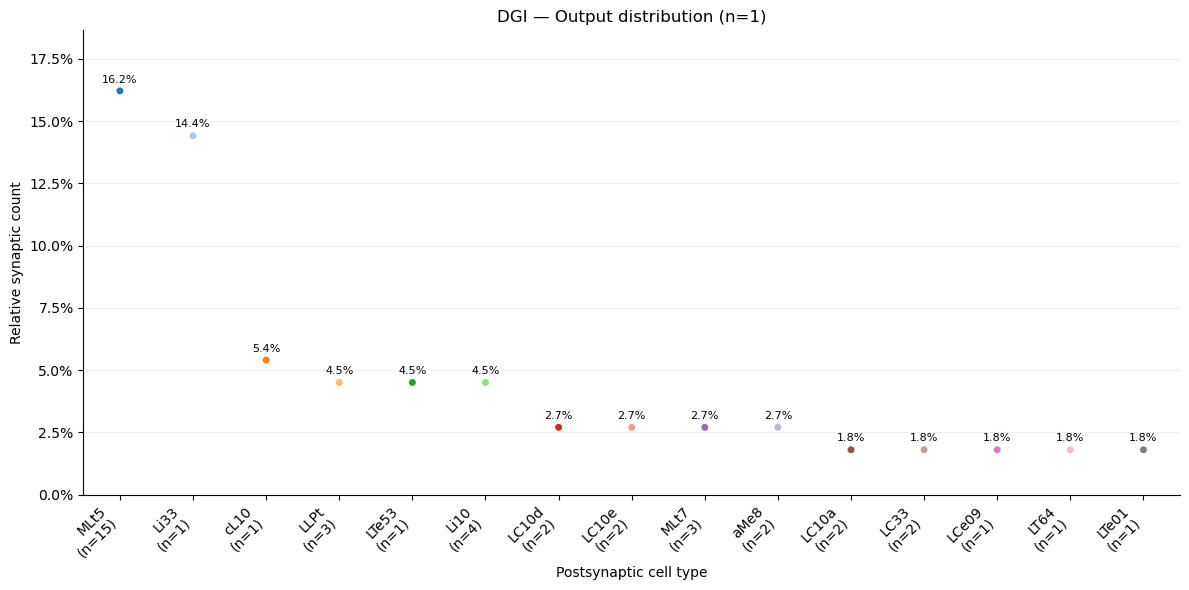

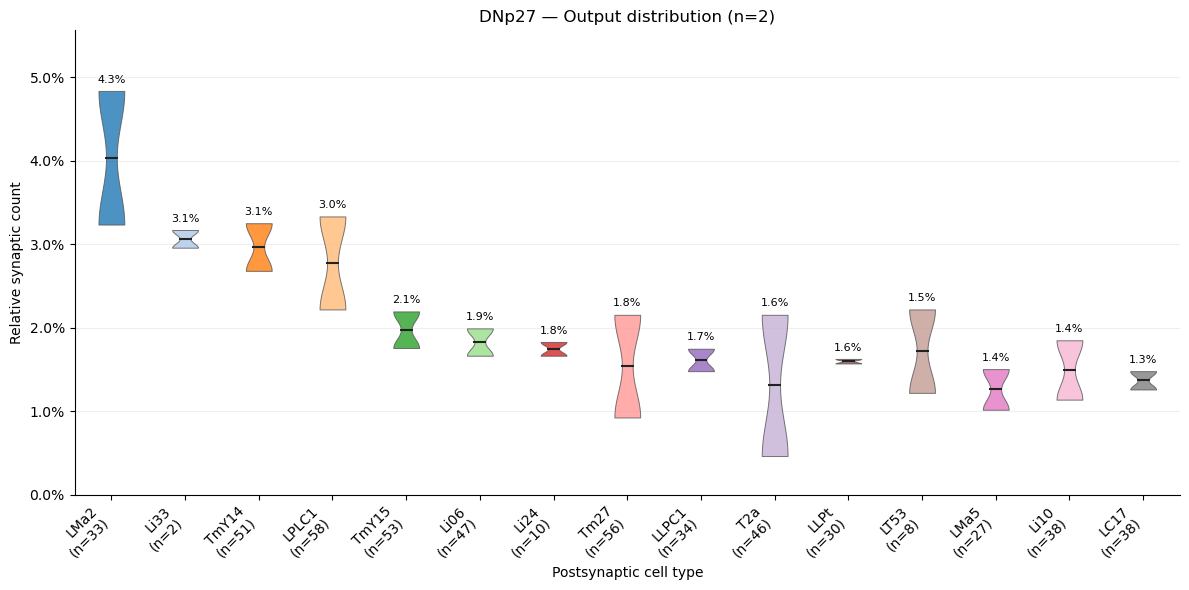

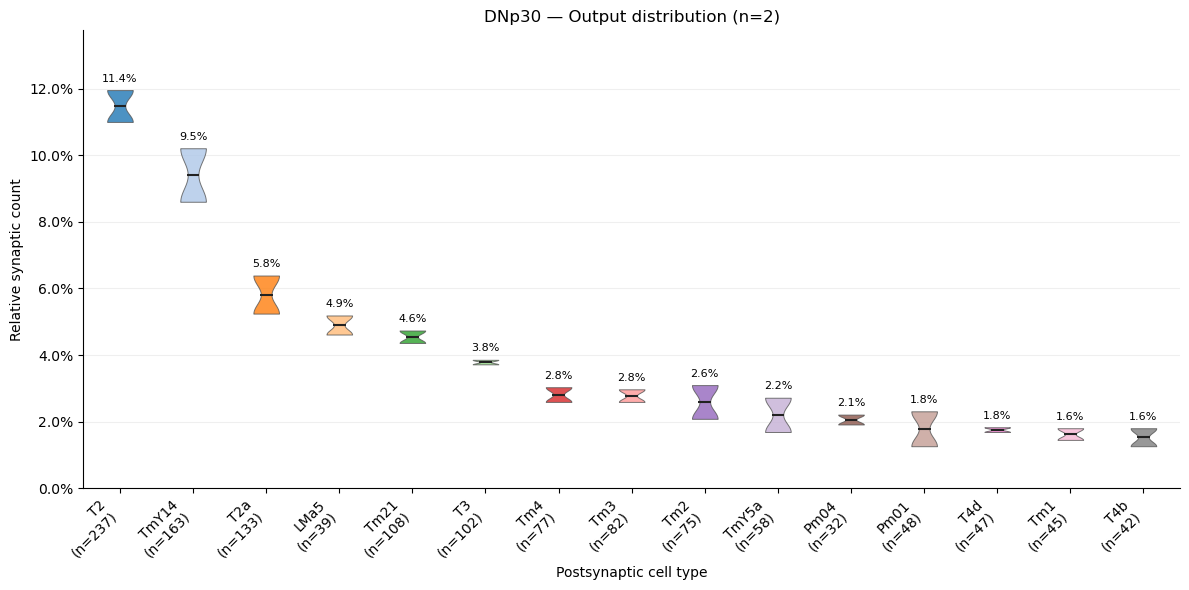

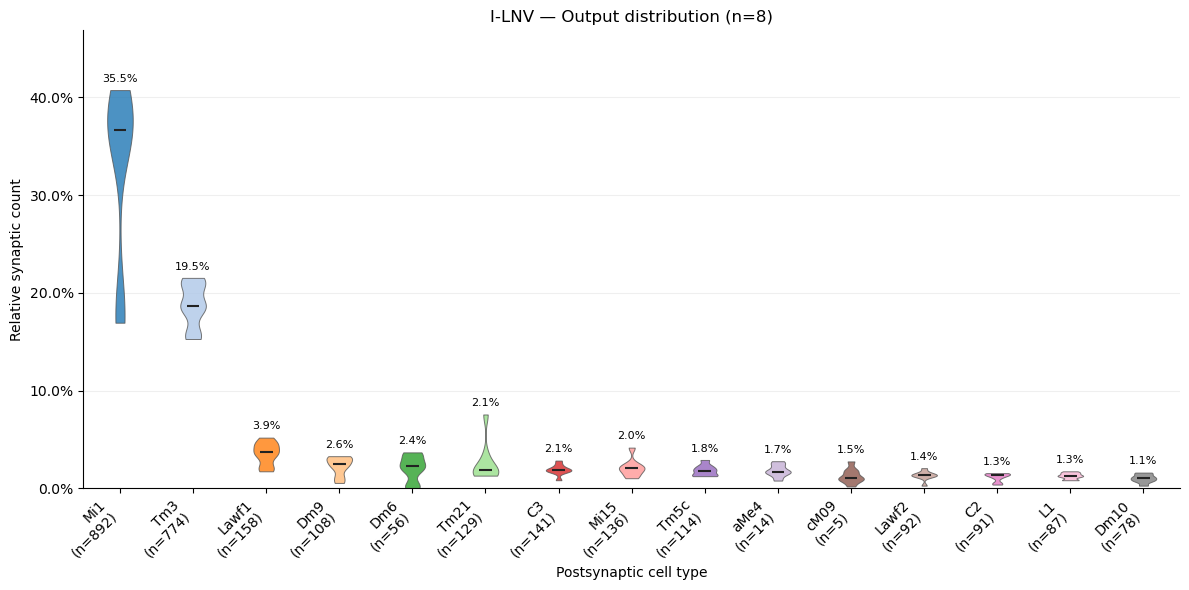

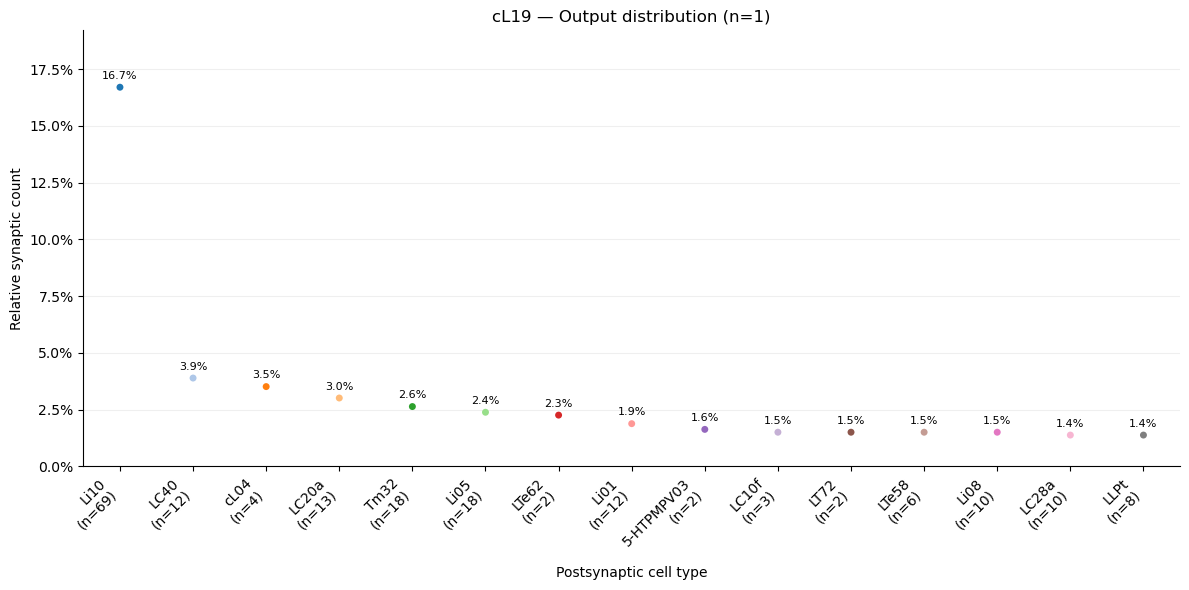

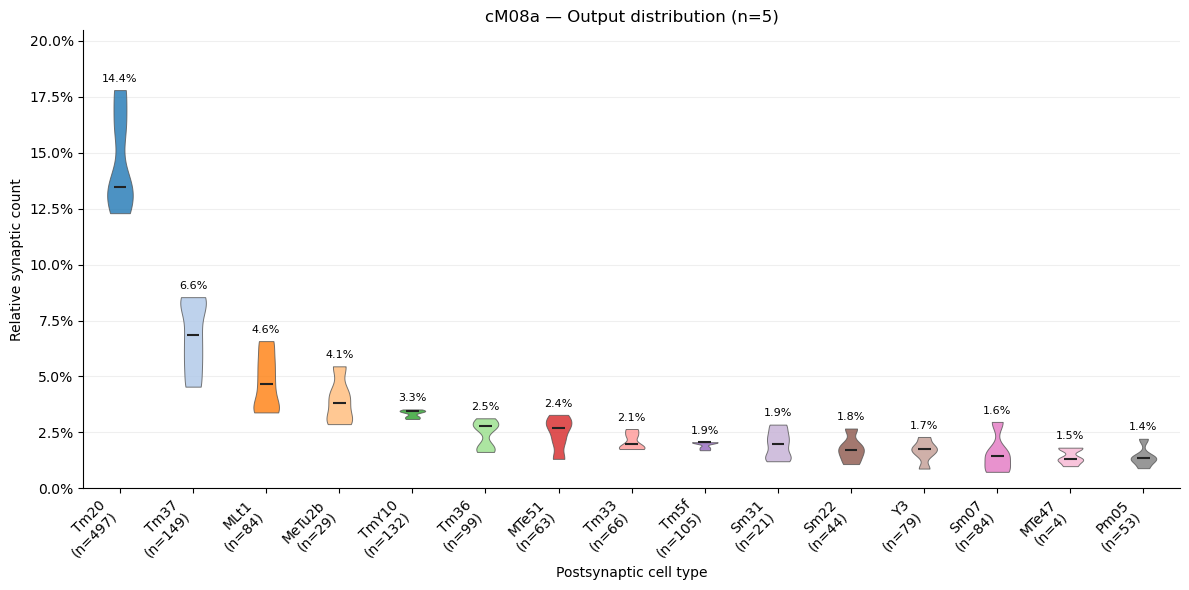

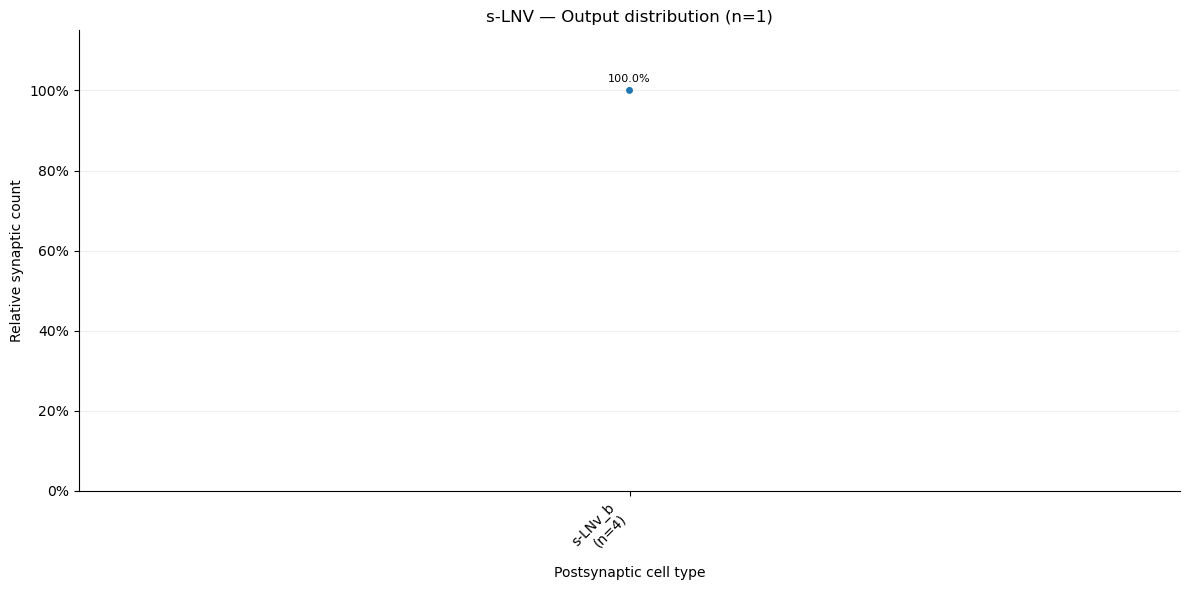

In [3]:
#plot for each neuropil showing the distribution of postsynaptic cell types for each presynaptic cell type.

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

df = pd.read_csv(
    "/Users/ndutta/Drive D/B mod/final_connections_fixed_names.csv",
    dtype={"pre_root_id": "string", "post_root_id": "string"}
)

pre, post = "pre_syn_cell_types", "post_syn_cell_types"
df[[pre, post]] = df[[pre, post]].fillna("Unannotated")
df["neuropil"] = df["neuropil"].str.replace(r"_[LR]$", "", regex=True)
df = df[df["neuropil"].isin(["ME", "LOP", "LO", "AME"]) & (df["syn_count"] > 0)]

colors = plt.get_cmap("tab20").colors

for name, data in df.groupby(pre):
    totals = data.groupby("pre_root_id")["syn_count"].sum()
    n = data.groupby(post)["post_root_id"].nunique()

    counts = data.pivot_table(
        index="pre_root_id", columns=post, values="syn_count",
        aggfunc="sum", fill_value=0
    )
    top = (
        counts.drop(columns="Unannotated", errors="ignore")
        .sum().nlargest(15).index
    )
    if len(top) == 0:
        continue

    relative = counts[top].div(totals, axis=0)
    pooled = counts[top].sum() / totals.sum()
    maximum = relative.max().max()

    fig, ax = plt.subplots(figsize=(12, 6))

    for i, cell in enumerate(top):
        values = relative[cell]
        color = colors[i % len(colors)]

        if values.nunique() > 1:
            violin = ax.violinplot(
                values, positions=[i], widths=.35, bw_method=.4,
                showextrema=False, showmedians=True
            )
            body = violin["bodies"][0]
            body.set_facecolor(color)
            body.set_edgecolor("#555555")
            body.set_linewidth(.7)
            body.set_alpha(.8)
            violin["cmedians"].set_color("#222222")
        else:
            ax.scatter(i, values.iloc[0], color=color,
                       edgecolors="none", s=25)

        ax.annotate(
            f"{pooled[cell]:.1%}", (i, values.max()),
            xytext=(0, 6), textcoords="offset points",
            ha="center", fontsize=8
        )

    ax.set_xticks(
        range(len(top)),
        [f"{cell}\n(n={n[cell]})" for cell in top],
        rotation=45, ha="right"
    )
    ax.set(
        title=f"{name} — Output distribution (n={len(totals)})",
        xlabel="Postsynaptic cell type",
        ylabel="Relative synaptic count",
        xlim=(-.5, len(top) - .5),
        ylim=(0, maximum + max(maximum * .15, .001))
    )
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=.2)
    ax.spines[["top", "right"]].set_visible(False)

    plt.tight_layout()
    plt.show()
    plt.close(fig)

In [4]:
#here this code fixes the cell type names in the connections file to match the visual annotation names
import pandas as pd

visual = pd.read_csv(
    "/Users/ndutta/Drive D/B mod/visual_neuron_types.csv",
    dtype={"root_id": "string"}
)


targets = [
    "Mi1", "Tm3", "Tm20", "TmY14", "T2", "Tm37", "Tm21", "T2a",
    "MLt1", "Lawf1", "MeTu2b", "LMa5", "TmY10", "Dm9", "TmY5a"
]

total = visual.groupby("type")["root_id"].nunique()

display(total.loc[targets])

type
Mi1       1581
Tm3       1755
Tm20      1494
TmY14      370
T2        1466
Tm37       238
Tm21      1291
T2a       1774
MLt1        92
Lawf1      280
MeTu2b      31
LMa5        76
TmY10      447
Dm9        205
TmY5a     1176
Name: root_id, dtype: int64

In [5]:

ser = pd.read_csv(
    "/Users/ndutta/Drive D/B mod/final_connections_fixed_names.csv",
    dtype={"post_root_id": "string"}
)

ser = ser[ser["syn_count"] > 0]

lookup = visual.set_index("root_id")["type"]
ser["post_type"] = ser["post_root_id"].map(lookup)

connected = ser.groupby("post_type")["post_root_id"].nunique()
connected = connected.reindex(targets, fill_value=0)

display(connected)

post_type
Mi1       900
Tm3       830
Tm20      531
TmY14     223
T2        296
Tm37      153
Tm21      257
T2a       252
MLt1       87
Lawf1     158
MeTu2b     29
LMa5       58
TmY10     145
Dm9       108
TmY5a     161
Name: post_root_id, dtype: int64

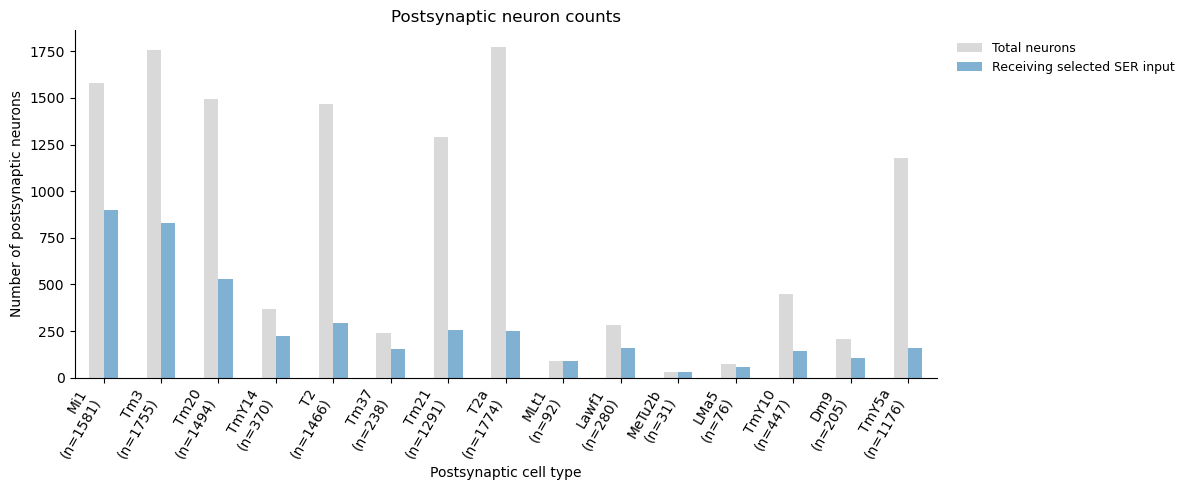

In [6]:
#plotting the number of postsynaptic neurons receiving input from selected SER neurons
import matplotlib.pyplot as plt

counts = pd.DataFrame()
counts["Total neurons"] = total.loc[targets]
counts["Receiving selected SER input"] = connected

ax = counts.plot.bar(
    figsize=(12, 5),
    color=["#D9D9D9", "#80B1D3"]
)

labels = []
for cell in targets:
    labels.append(f"{cell}\n(n={int(total[cell])})")

ax.set_xticklabels(labels, rotation=60, ha="right")
ax.set_title("Postsynaptic neuron counts")
ax.set_xlabel("Postsynaptic cell type")
ax.set_ylabel("Number of postsynaptic neurons")

ax.legend(
    loc="upper left", bbox_to_anchor=(1.01, 1),
    frameon=False, fontsize=9
)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

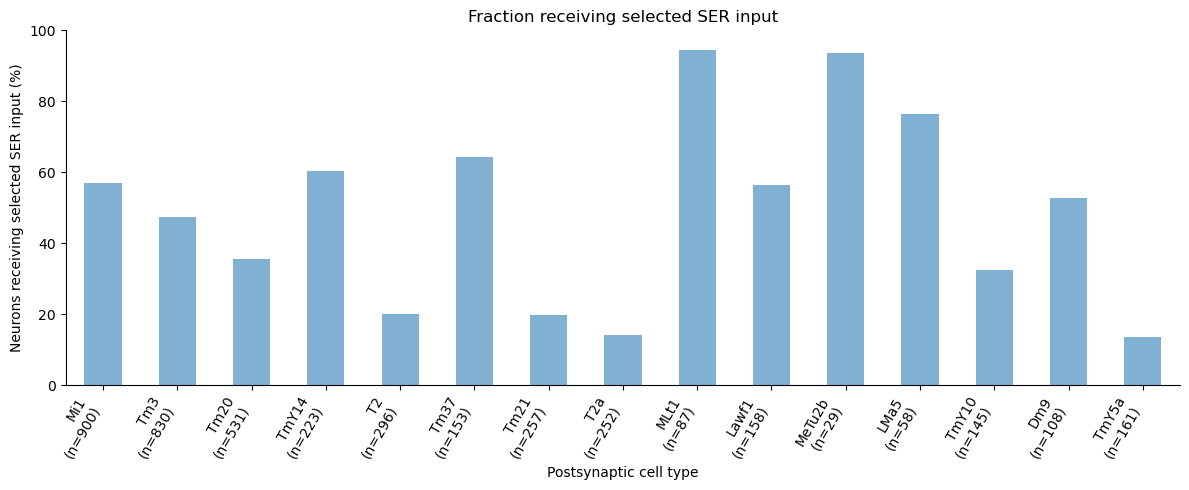

In [7]:
#plotting the fraction of postsynaptic neurons receiving input from selected SER neurons
percentage = connected / total.loc[targets] * 100

ax = percentage.plot.bar(
    figsize=(12, 5),
    color="#80B1D3"
)

labels = []
for cell in targets:
    labels.append(f"{cell}\n(n={int(connected[cell])})")

ax.set_xticklabels(labels, rotation=60, ha="right")
ax.set_title("Fraction receiving selected SER input")
ax.set_xlabel("Postsynaptic cell type")
ax.set_ylabel("Neurons receiving selected SER input (%)")
ax.set_ylim(0, 100)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

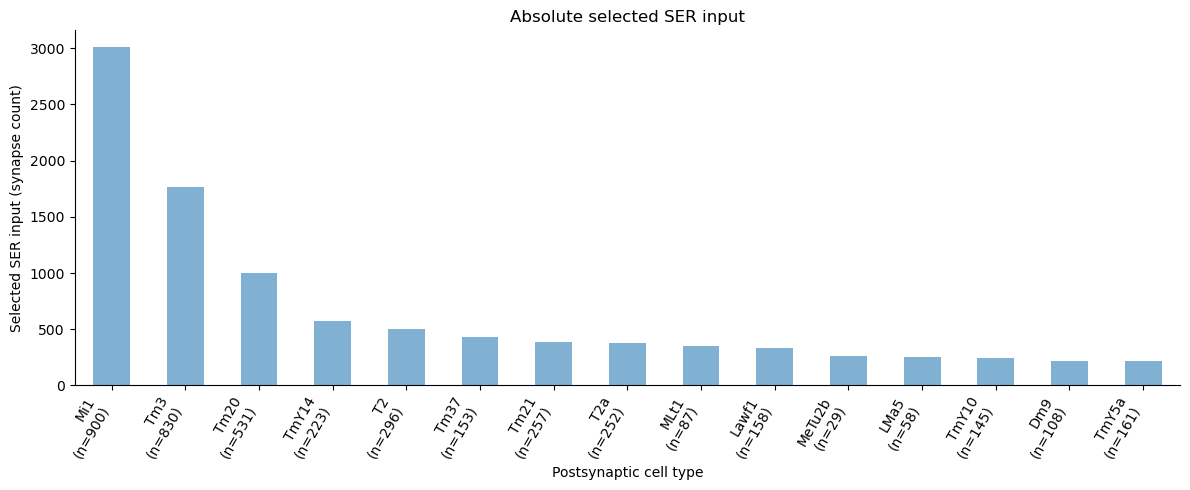

In [8]:
#plotting the absolute number of synapses received by postsynaptic neurons from selected SER neurons

synapses = ser.groupby("post_type")["syn_count"].sum()
synapses = synapses.reindex(targets, fill_value=0)

ax = synapses.plot.bar(
    figsize=(12, 5),
    color="#80B1D3"
)

labels = []
for cell in targets:
    labels.append(f"{cell}\n(n={int(connected[cell])})")

ax.set_xticklabels(labels, rotation=60, ha="right")
ax.set_title("Absolute selected SER input")
ax.set_xlabel("Postsynaptic cell type")
ax.set_ylabel("Selected SER input (synapse count)")
ax.set_ylim(bottom=0)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

In [9]:
# the total number of synapses received by postsynaptic neurons from selected SER neurons

target_ids = visual.loc[visual["type"].isin(targets), "root_id"]

parts = []

for chunk in pd.read_csv(
    "/Users/ndutta/Drive D/B mod/connections_princeton_no_threshold.csv",
    usecols=["post_root_id", "syn_count"],
    dtype={"post_root_id": "string"},
    chunksize=500_000
):
    chunk = chunk[chunk["post_root_id"].isin(target_ids)]
    counts = chunk.groupby("post_root_id")["syn_count"].sum()
    parts.append(counts)

inputs = pd.concat(parts).groupby(level=0).sum()

assert target_ids.isin(inputs.index).all(), "Some neuron IDs are missing."

input_table = inputs.to_frame("total_input")
input_table["post_type"] = input_table.index.map(lookup)

total_input = input_table.groupby("post_type")["total_input"].sum()
total_input = total_input.reindex(targets)

display(total_input)

post_type
Mi1       665535
Tm3       595493
Tm20      341822
TmY14     521715
T2        694617
Tm37       76489
Tm21      461466
T2a       579120
MLt1       48878
Lawf1     171845
MeTu2b     11410
LMa5      397591
TmY10     129566
Dm9       147606
TmY5a     642156
Name: total_input, dtype: int64

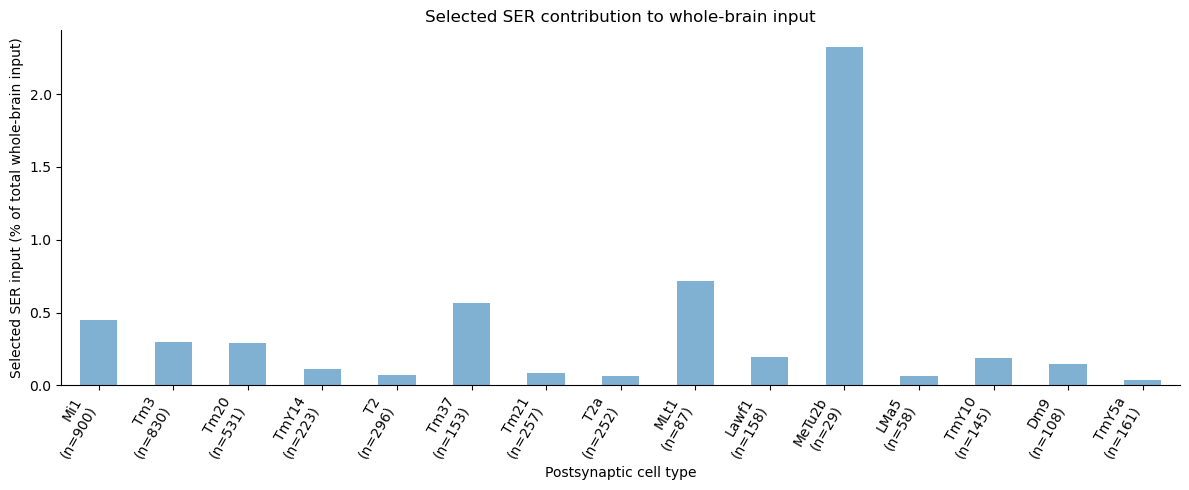

In [10]:
#plotting the fraction of postsynaptic neurons receiving input from selected SER neurons

assert total_input.gt(0).all(), "Check total input counts."
assert synapses.le(total_input).all(), "Check input counts."

ser_percentage = synapses / total_input * 100

ax = ser_percentage.plot.bar(
    figsize=(12, 5),
    color="#80B1D3"
)

labels = []
for cell in targets:
    labels.append(f"{cell}\n(n={int(connected[cell])})")

ax.set_xticklabels(labels, rotation=60, ha="right")
ax.set_title("Selected SER contribution to whole-brain input")
ax.set_xlabel("Postsynaptic cell type")
ax.set_ylabel("Selected SER input (% of total whole-brain input)")
ax.set_ylim(bottom=0)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

In [11]:
# Summary table for selected SER neurons

summary = pd.DataFrame(index=targets)

summary["Total neurons"] = total.loc[targets]
summary["SER-connected neurons"] = connected
summary["SER-connected neurons (%)"] = percentage
summary["Selected SER synapses"] = synapses
summary["Total whole-brain input"] = total_input
summary["SER / whole-brain input (%)"] = ser_percentage

display(summary.round(2))

,Total neurons,SER-connected neurons,SER-connected neurons (%),Selected SER synapses,Total whole-brain input,SER / whole-brain input (%)
Mi1,1581,900,56.93,3009,665535,0.45
Tm3,1755,830,47.29,1765,595493,0.30
Tm20,1494,531,35.54,1001,341822,0.29
TmY14,370,223,60.27,574,521715,0.11
T2,1466,296,20.19,500,694617,0.07
Tm37,238,153,64.29,434,76489,0.57
Tm21,1291,257,19.91,389,461466,0.08
T2a,1774,252,14.21,377,579120,0.07
MLt1,92,87,94.57,352,48878,0.72
Lawf1,280,158,56.43,331,171845,0.19


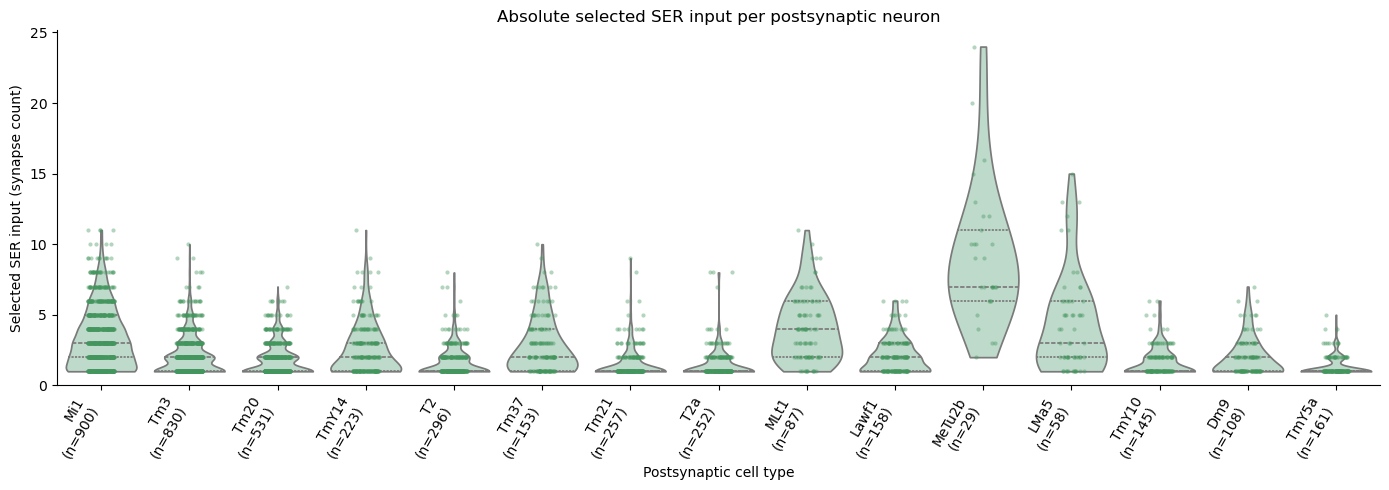

In [ ]:
#violin plot for each postsynaptic cell type showing the distribution of synapse counts received from selected SER neurons

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

folder = "/Users/ndutta/Drive D/B mod/"

ser = pd.read_csv(
    folder + "final_connections_fixed_names.csv",
    dtype={"post_root_id": "string"}
)
visual = pd.read_csv(
    folder + "visual_neuron_types.csv",
    dtype={"root_id": "string"}
)

lookup = visual.set_index("root_id")["type"].str.strip()
assert lookup.index.is_unique, "Duplicate IDs in visual annotation."

targets = [
    "Mi1", "Tm3", "Tm20", "TmY14", "T2", "Tm37", "Tm21", "T2a",
    "MLt1", "Lawf1", "MeTu2b", "LMa5", "TmY10", "Dm9", "TmY5a"
]

data = ser.groupby("post_root_id")["syn_count"].sum().to_frame("ser_input")
data["post_type"] = data.index.map(lookup)
data = data[
    data["post_type"].isin(targets) & (data["ser_input"] > 0)
].copy()

parts = []
for chunk in pd.read_csv(
    folder + "connections_princeton_no_threshold.csv",
    usecols=["post_root_id", "syn_count"],
    dtype={"post_root_id": "string"},
    chunksize=500_000
):
    chunk = chunk[chunk["post_root_id"].isin(data.index)]
    parts.append(chunk.groupby("post_root_id")["syn_count"].sum())

total_input = pd.concat(parts).groupby(level=0).sum()
data["total_input"] = total_input.reindex(data.index)

assert (data["ser_input"] <= data["total_input"]).all(), \
    "Check missing IDs or input counts."

n = data.groupby("post_type").size()

fig, ax = plt.subplots(figsize=(14, 5))

sns.violinplot(
    data=data[data["post_type"].map(n) >= 5],
    x="post_type", y="ser_input", order=targets,
    color="#B9DFCA", inner="quart", cut=0,
    density_norm="width", ax=ax
)
sns.stripplot(
    data=data, x="post_type", y="ser_input", order=targets,
    color="#43965D", size=3, alpha=.4,
    jitter=.15, linewidth=0, ax=ax
)

ax.set_xticks(
    range(len(targets)),
    labels=[f"{t}\n(n={n.get(t, 0)})" for t in targets],
    rotation=60, ha="right"
)
ax.set(
    title="Absolute selected SER input per postsynaptic neuron",
    xlabel="Postsynaptic cell type",
    ylabel="Selected SER input (synapse count)",
    ylim=(0, None)
)

sns.despine()
plt.tight_layout()
plt.show()

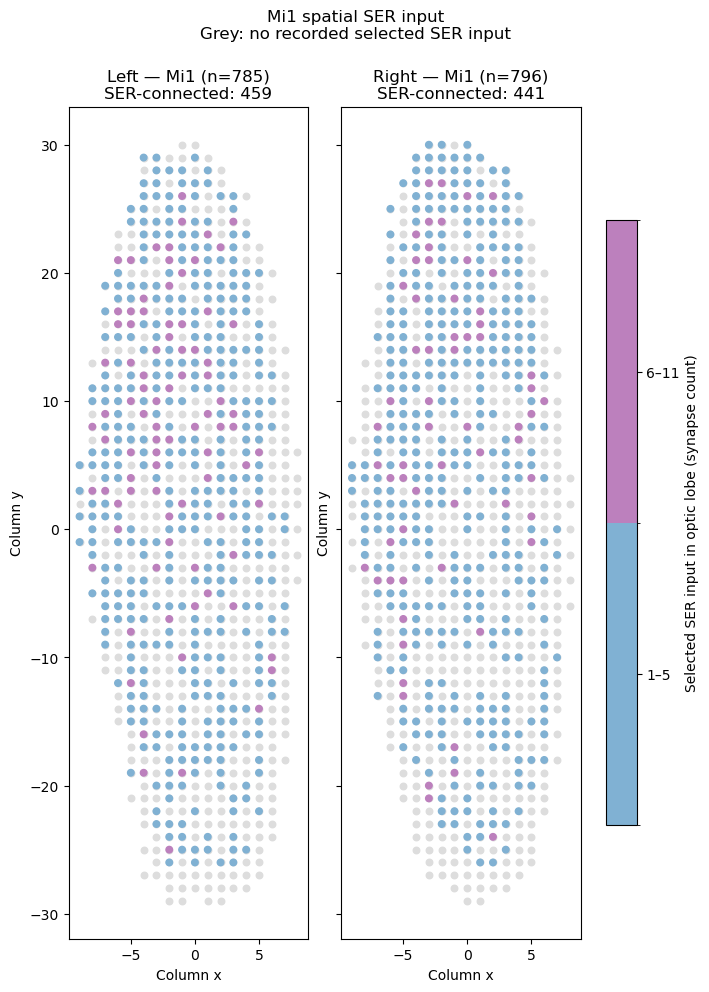

In [12]:
#plotting the spatial distribution of Mi1 neurons receiving input from selected SER neurons

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm

folder = "/Users/ndutta/Drive D/B mod/"

ser = pd.read_csv(
    folder + "final_connections_fixed_names.csv",
    dtype={"post_root_id": "string"}
)
assignment = pd.read_csv(
    folder + "column_assignment (1).csv",
    dtype={"root_id": "string"}
)

mi1_map = assignment[assignment["type"] == "Mi1"].copy()
assert mi1_map["root_id"].is_unique, "Duplicate Mi1 IDs."


ser["neuropil"] = ser["neuropil"].str.replace(r"_[LR]$", "", regex=True)
ser = ser[
    ser["neuropil"].isin(["ME", "LO", "LOP", "AME"])
    & (ser["syn_count"] > 0)
]
inputs = ser.groupby("post_root_id")["syn_count"].sum()
mi1_map["ser_input"] = mi1_map["root_id"].map(inputs).fillna(0).astype(int)


colors = ["#80B1D3", "#BC80BD"]
maximum = max(1, int(mi1_map["ser_input"].max()))
bins = min(2, maximum)
edges = np.linspace(0, maximum, bins + 1).astype(int) + .5
cmap = ListedColormap(colors[:bins])
norm = BoundaryNorm(edges, cmap.N)

fig, axes = plt.subplots(
    1, 2, figsize=(7, 10),
    sharex=True, sharey=True, layout="constrained"
)

for ax, side in zip(axes, ["left", "right"]):
    cells = mi1_map[mi1_map["hemisphere"] == side]
    receiving = cells[cells["ser_input"] > 0]

    ax.scatter(cells["x"], cells["y"], color="#DDDDDD", s=22)
    points = ax.scatter(
        receiving["x"], receiving["y"],
        c=receiving["ser_input"], cmap=cmap, norm=norm, s=22
    )

    ax.set_title(
        f"{side.title()} — Mi1 (n={len(cells)})\n"
        f"SER-connected: {len(receiving)}"
    )
    ax.set_xlabel("Column x")
    ax.set_ylabel("Column y")
    ax.set_aspect("equal")

bar = fig.colorbar(
    points, ax=axes, shrink=.65,
    ticks=(edges[:-1] + edges[1:]) / 2,
    label="Selected SER input in optic lobe (synapse count)"
)
bar.set_ticklabels([
    f"{int(np.ceil(a))}–{int(np.floor(b))}"
    for a, b in zip(edges[:-1], edges[1:])
])

fig.suptitle(
    "Mi1 spatial SER input\nGrey: no recorded selected SER input"
)
plt.show()

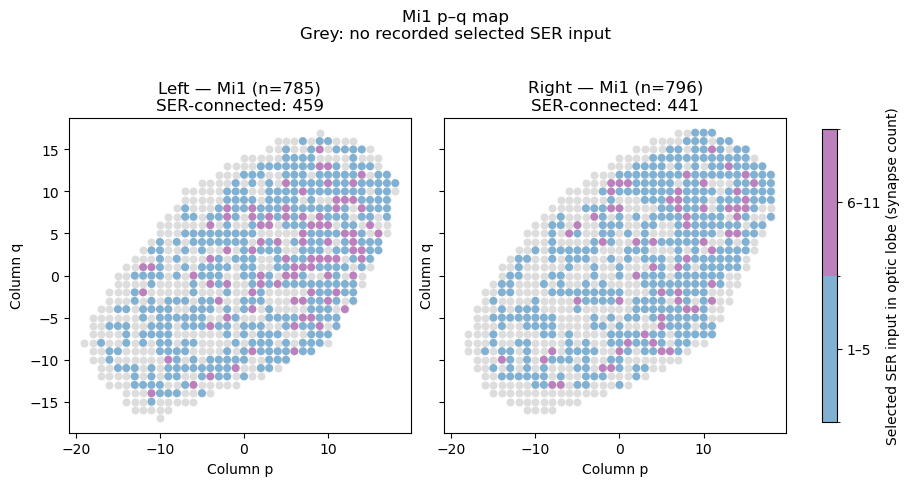

In [13]:
#plotting the spatial distribution of Mi1 neurons receiving input from selected SER neurons

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm

folder = "/Users/ndutta/Drive D/B mod/"

ser = pd.read_csv(
    folder + "final_connections_fixed_names.csv",
    dtype={"post_root_id": "string"}
)
assignment = pd.read_csv(
    folder + "column_assignment (1).csv",
    dtype={"root_id": "string"}
)

mi1_map = assignment[assignment["type"] == "Mi1"].copy()
mi1_map = mi1_map.dropna(subset=["p", "q"])
assert mi1_map["root_id"].is_unique, "Duplicate Mi1 IDs."

#   Sum selected SER input within the optic lobe
ser["neuropil"] = ser["neuropil"].str.replace(r"_[LR]$", "", regex=True)
ser = ser[
    ser["neuropil"].isin(["ME", "LO", "LOP", "AME"])
    & (ser["syn_count"] > 0)
]
inputs = ser.groupby("post_root_id")["syn_count"].sum()
mi1_map["ser_input"] = mi1_map["root_id"].map(inputs).fillna(0).astype(int)

colors = ["#80B1D3", "#BC80BD"]
maximum = max(1, int(mi1_map["ser_input"].max()))
bins = min(2, maximum)
edges = np.linspace(0, maximum, bins + 1).astype(int) + .5
cmap = ListedColormap(colors[:bins])
norm = BoundaryNorm(edges, cmap.N)

fig, axes = plt.subplots(
    1, 2, figsize=(9, 5),
    sharex=True, sharey=True, layout="constrained"
)

for ax, side in zip(axes, ["left", "right"]):
    cells = mi1_map[mi1_map["hemisphere"] == side]
    receiving = cells[cells["ser_input"] > 0]

    ax.scatter(cells["p"], cells["q"], color="#DDDDDD", s=22)
    points = ax.scatter(
        receiving["p"], receiving["q"],
        c=receiving["ser_input"], cmap=cmap, norm=norm, s=22
    )

    ax.set_title(
        f"{side.title()} — Mi1 (n={len(cells)})\n"
        f"SER-connected: {len(receiving)}"
    )
    ax.set_xlabel("Column p")
    ax.set_ylabel("Column q")
    ax.set_aspect("equal")

bar = fig.colorbar(
    points, ax=axes, shrink=.65,
    ticks=(edges[:-1] + edges[1:]) / 2,
    label="Selected SER input in optic lobe (synapse count)"
)
bar.set_ticklabels([
    f"{int(np.ceil(a))}–{int(np.floor(b))}"
    for a, b in zip(edges[:-1], edges[1:])
])

fig.suptitle(
    "Mi1 p–q map\nGrey: no recorded selected SER input"
)
plt.show()

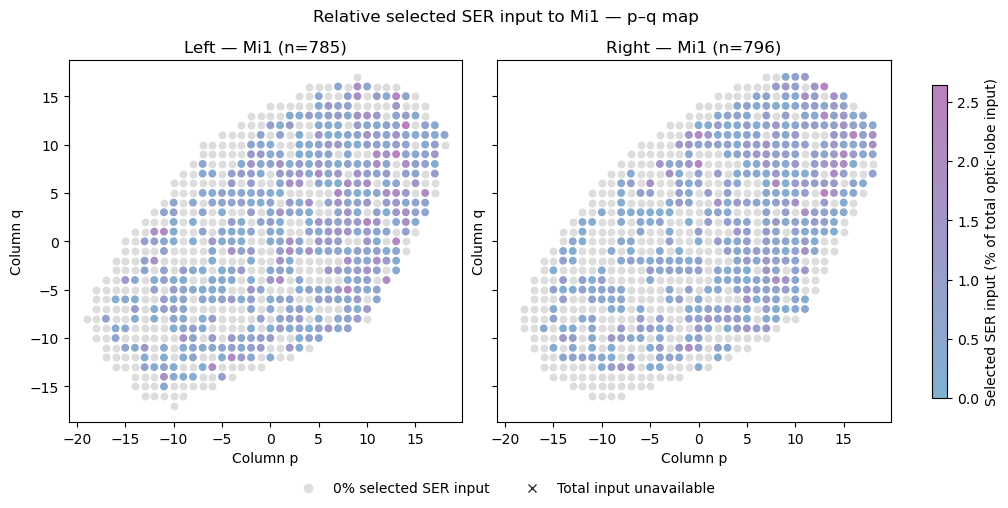

In [14]:
#plotting the spatial distribution of Mi1 neurons receiving input from selected SER neurons

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.lines import Line2D
from matplotlib.cm import ScalarMappable

folder = "/Users/ndutta/Drive D/B mod/"
regions = ["ME", "LO", "LOP", "AME"]

# Mi1 neurons and their coordinates
assignment = pd.read_csv(
    folder + "column_assignment (1).csv",
    dtype={"root_id": "string"}
)
mapped = assignment.loc[
    assignment["type"] == "Mi1",
    ["root_id", "hemisphere", "p", "q"]
].dropna(subset=["p", "q"]).copy()

assert mapped["root_id"].is_unique, "Duplicate Mi1 IDs."

ser = pd.read_csv(
    folder + "final_connections_fixed_names.csv",
    dtype={"post_root_id": "string"}
)
ser["neuropil"] = ser["neuropil"].str.replace(r"_[LR]$", "", regex=True)
ser = ser[
    ser["neuropil"].isin(regions) & (ser["syn_count"] > 0)
]
ser_input = ser.groupby("post_root_id")["syn_count"].sum()
mapped["ser_input"] = mapped["root_id"].map(ser_input).fillna(0)

parts = []
for chunk in pd.read_csv(
    folder + "connections_princeton_no_threshold.csv",
    usecols=["post_root_id", "neuropil", "syn_count"],
    dtype={"post_root_id": "string"},
    chunksize=500_000
):
    chunk["neuropil"] = chunk["neuropil"].str.replace(
        r"_[LR]$", "", regex=True
    )
    chunk = chunk[
        chunk["post_root_id"].isin(mapped["root_id"])
        & chunk["neuropil"].isin(regions)
    ]
    parts.append(chunk.groupby("post_root_id")["syn_count"].sum())

total_input = pd.concat(parts).groupby(level=0).sum()
mapped["total_input"] = mapped["root_id"].map(total_input)

known = mapped.dropna(subset=["total_input"])
assert (known["ser_input"] <= known["total_input"]).all(), "Check input counts."

mapped["SER_percent"] = (
    mapped["ser_input"]
    / mapped["total_input"].where(mapped["total_input"] > 0) * 100
)

maximum = mapped["SER_percent"].max()
assert pd.notna(maximum), "No valid optic-lobe input totals."

cmap = LinearSegmentedColormap.from_list(
    "blue_purple", ["#80B1D3", "#BC80BD"]
)
norm = Normalize(0, max(maximum, .01))

fig, axes = plt.subplots(
    1, 2, figsize=(10, 5),
    sharex=True, sharey=True, layout="constrained"
)

for ax, side in zip(axes, ["left", "right"]):
    cells = mapped[mapped["hemisphere"] == side]
    zero = cells[cells["SER_percent"] == 0]
    positive = cells[cells["SER_percent"] > 0]
    missing = cells[cells["SER_percent"].isna()]

    ax.scatter(zero["p"], zero["q"], color="#DDDDDD", s=22)
    ax.scatter(
        positive["p"], positive["q"],
        c=positive["SER_percent"], cmap=cmap, norm=norm, s=22
    )
    ax.scatter(
        missing["p"], missing["q"],
        color="#333333", marker="x", s=22
    )

    ax.set_title(f"{side.title()} — Mi1 (n={len(cells)})")
    ax.set_xlabel("Column p")
    ax.set_ylabel("Column q")
    ax.set_aspect("equal")

fig.colorbar(
    ScalarMappable(norm=norm, cmap=cmap),
    ax=axes, shrink=.75,
    label="Selected SER input (% of total optic-lobe input)"
)

fig.legend(
    handles=[
        Line2D([], [], marker="o", linestyle="", color="#DDDDDD",
               label="0% selected SER input"),
        Line2D([], [], marker="x", linestyle="", color="#333333",
               label="Total input unavailable")
    ],
    loc="outside lower center", ncol=2, frameon=False
)

fig.suptitle("Relative selected SER input to Mi1 — p–q map")
plt.show()

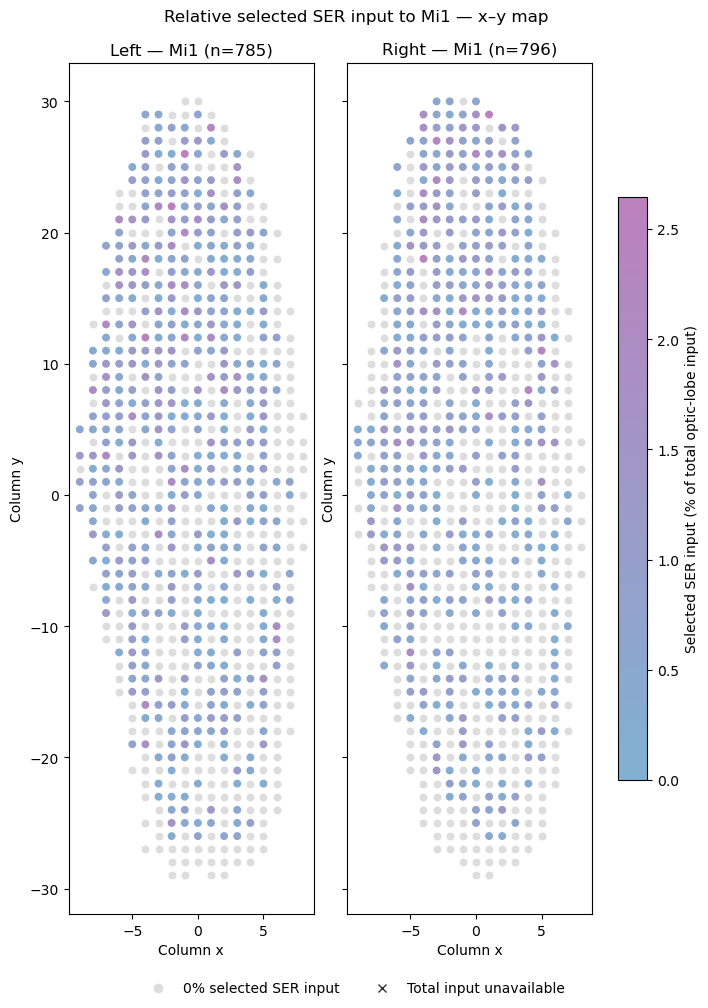

In [15]:
#plotting the spatial distribution of Mi1 neurons receiving input from selected SER neurons

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.lines import Line2D
from matplotlib.cm import ScalarMappable

folder = "/Users/ndutta/Drive D/B mod/"
regions = ["ME", "LO", "LOP", "AME"]


assignment = pd.read_csv(
    folder + "column_assignment (1).csv",
    dtype={"root_id": "string"}
)
xy_map = assignment.loc[
    assignment["type"] == "Mi1",
    ["root_id", "hemisphere", "x", "y"]
].dropna(subset=["x", "y"]).copy()

assert xy_map["root_id"].is_unique, "Duplicate Mi1 IDs."


ser = pd.read_csv(
    folder + "final_connections_fixed_names.csv",
    dtype={"post_root_id": "string"}
)
ser["neuropil"] = ser["neuropil"].str.replace(r"_[LR]$", "", regex=True)
ser = ser[
    ser["neuropil"].isin(regions) & (ser["syn_count"] > 0)
]
ser_input = ser.groupby("post_root_id")["syn_count"].sum()
xy_map["ser_input"] = xy_map["root_id"].map(ser_input).fillna(0)

parts = []
for chunk in pd.read_csv(
    folder + "connections_princeton_no_threshold.csv",
    usecols=["post_root_id", "neuropil", "syn_count"],
    dtype={"post_root_id": "string"},
    chunksize=500_000
):
    chunk["neuropil"] = chunk["neuropil"].str.replace(
        r"_[LR]$", "", regex=True
    )
    chunk = chunk[
        chunk["post_root_id"].isin(xy_map["root_id"])
        & chunk["neuropil"].isin(regions)
    ]
    parts.append(chunk.groupby("post_root_id")["syn_count"].sum())

total_input = pd.concat(parts).groupby(level=0).sum()
xy_map["total_input"] = xy_map["root_id"].map(total_input)

known = xy_map.dropna(subset=["total_input"])
assert (known["ser_input"] <= known["total_input"]).all(), "Check input counts."

xy_map["SER_percent"] = (
    xy_map["ser_input"]
    / xy_map["total_input"].where(xy_map["total_input"] > 0) * 100
)

maximum = xy_map["SER_percent"].max()
assert pd.notna(maximum), "No valid optic-lobe input totals."

cmap = LinearSegmentedColormap.from_list(
    "blue_purple", ["#80B1D3", "#BC80BD"]
)
norm = Normalize(0, max(maximum, .01))

fig, axes = plt.subplots(
    1, 2, figsize=(7, 10),
    sharex=True, sharey=True, layout="constrained"
)

for ax, side in zip(axes, ["left", "right"]):
    cells = xy_map[xy_map["hemisphere"] == side]
    zero = cells[cells["SER_percent"] == 0]
    positive = cells[cells["SER_percent"] > 0]
    missing = cells[cells["SER_percent"].isna()]

    ax.scatter(zero["x"], zero["y"], color="#DDDDDD", s=22)
    ax.scatter(
        positive["x"], positive["y"],
        c=positive["SER_percent"], cmap=cmap, norm=norm, s=22
    )
    ax.scatter(
        missing["x"], missing["y"],
        color="#333333", marker="x", s=22
    )

    ax.set_title(f"{side.title()} — Mi1 (n={len(cells)})")
    ax.set_xlabel("Column x")
    ax.set_ylabel("Column y")
    ax.set_aspect("equal")

fig.colorbar(
    ScalarMappable(norm=norm, cmap=cmap),
    ax=axes, shrink=.65,
    label="Selected SER input (% of total optic-lobe input)"
)

fig.legend(
    handles=[
        Line2D([], [], marker="o", linestyle="", color="#DDDDDD",
               label="0% selected SER input"),
        Line2D([], [], marker="x", linestyle="", color="#333333",
               label="Total input unavailable")
    ],
    loc="outside lower center", ncol=2, frameon=False
)

fig.suptitle("Relative selected SER input to Mi1 — x–y map")
plt.show()

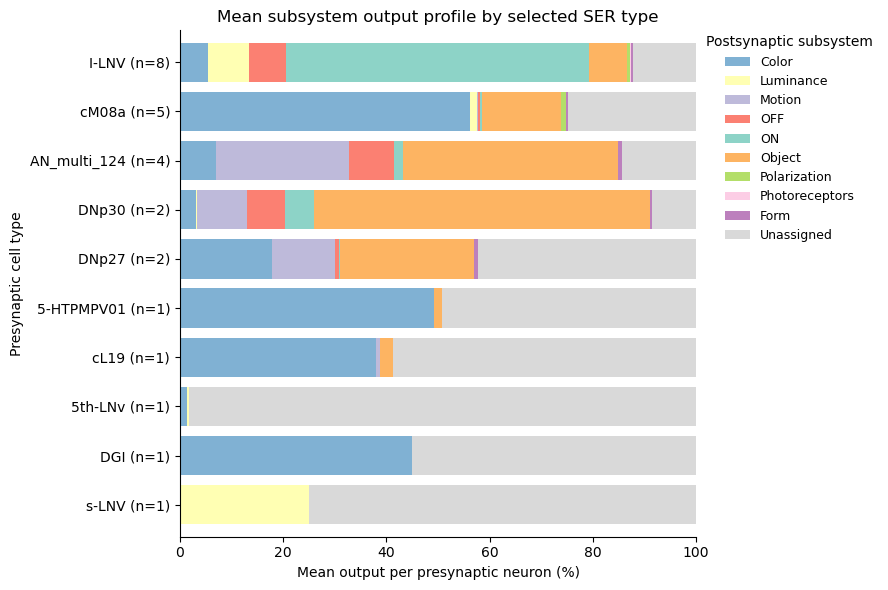

In [16]:
# plotting the mean output profile of selected SER neurons across postsynaptic subsystems

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

folder = "/Users/ndutta/Drive D/B mod/"

df = pd.read_csv(
    folder + "final_connections_fixed_names.csv",
    dtype={"pre_root_id": "string", "post_root_id": "string"}
)
visual = pd.read_csv(
    folder + "visual_neuron_types.csv",
    dtype={"root_id": "string"}
)
df = df[df["syn_count"] > 0].copy()

# Assign postsynaptic subsystems
lookup = visual.set_index("root_id")["subsystem"]
assert lookup.index.is_unique, "Duplicate IDs in visual annotation."

df["subsystem"] = (
    df["post_root_id"].map(lookup).astype("string").str.strip()
    .replace({"": "Unassigned", "unassigned": "Unassigned"})
    .fillna("Unassigned")
)

# Calculate each presynaptic neuron's output percentages
counts = df.pivot_table(
    index="pre_root_id", columns="subsystem",
    values="syn_count", aggfunc="sum", fill_value=0
)
percent = counts.div(counts.sum(axis=1), axis=0) * 100

assert df.groupby("pre_root_id")["pre_syn_cell_types"].nunique().le(1).all(), \
    "Some presynaptic IDs have conflicting type labels."

types = df.groupby("pre_root_id")["pre_syn_cell_types"].first()
types = types.reindex(percent.index).fillna("Unknown")
n = types.value_counts()

groups = [
    "I-LNV", "cM08a", "AN_multi_124", "DNp30", "DNp27",
    "5-HTPMPV01", "cL19", "5th-LNv", "DGI", "s-LNV"
]
groups = [g for g in groups if g in n.index]
groups += [g for g in n.index if g not in groups]

palette = {
    "Color": "#80B1D3",
    "Luminance": "#FFFFB3",
    "Motion": "#BEBADA",
    "OFF": "#FB8072",
    "ON": "#8DD3C7",
    "Object": "#FDB462",
    "Polarization": "#B3DE69",
    "Photoreceptors": "#FCCDE5",
    "Form": "#BC80BD",
    "Unassigned": "#D9D9D9"
}

missing = set(percent.columns) - set(palette)
assert not missing, f"Add subsystem colours for: {missing}"

columns = [c for c in palette if c in percent.columns]

# Average percentages within each presynaptic type
mean = percent.groupby(types).mean().reindex(
    index=groups, columns=columns
)

ax = mean.plot.barh(
    stacked=True, figsize=(9, 6), width=.8,
    color=[palette[c] for c in mean.columns]
)

ax.set_yticks(
    range(len(mean)),
    labels=[f"{g} (n={n[g]})" for g in mean.index]
)
ax.invert_yaxis()
ax.set(
    xlim=(0, 100),
    xlabel="Mean output per presynaptic neuron (%)",
    ylabel="Presynaptic cell type",
    title="Mean subsystem output profile by selected SER type"
)
ax.legend(
    title="Postsynaptic subsystem",
    bbox_to_anchor=(1.01, 1), loc="upper left",
    frameon=False, borderaxespad=0, fontsize=9
)

sns.despine()
plt.tight_layout()
plt.show()